# Lab 2: Cats vs Dogs

In this lab, you will train a convolutional neural network to classify an image 
into one of two classes: "cat" or "dog". The code for the neural networks 
you train will be written for you, and you are not (yet!) expected
to understand all provided code. However, by the end of the lab,
you should be able to:

1. Understand at a high level the training loop for a machine learning model.
2. Understand the distinction between training, validation, and test data.
3. The concepts of overfitting and underfitting.
4. Investigate how different hyperparameters, such as learning rate and batch size, affect the success of training.
5. Compare an ANN (aka Multi-Layer Perceptron) with a CNN.

### What to submit

Submit a PDF file containing all your code, outputs, and write-up
from parts 1-5. You can produce a PDF of your Google Colab file by
going to **File > Print** and then save as PDF. The Colab instructions
has more information.

**Do not submit any other files produced by your code.**

Include a link to your colab file in your submission.

Please use Google Colab to complete this assignment. If you want to use Jupyter Notebook, please complete the assignment and upload your Jupyter Notebook file to Google Colab for submission. 

With Colab, you can export a PDF file using the menu option
`File -> Print` and save as PDF file. **Adjust the scaling to ensure that the text is not cutoff at the margins.**

## Colab Link

Include a link to your colab file here

Colab Link: 

In [2]:
import numpy as np
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data.sampler import SubsetRandomSampler
import torchvision.transforms as transforms


## Part 0. Helper Functions

We will be making use of the following helper functions. You will be asked to look
at and possibly modify some of these, but you are not expected to understand all of them.

You should look at the function names and read the docstrings. If you are curious, come back and explore the code *after* making some progress on the lab.

In [3]:
###############################################################################
# Data Loading

def get_relevant_indices(dataset, classes, target_classes):
    """ Return the indices for datapoints in the dataset that belongs to the
    desired target classes, a subset of all possible classes.

    Args:
        dataset: Dataset object
        classes: A list of strings denoting the name of each class
        target_classes: A list of strings denoting the name of desired classes
                        Should be a subset of the 'classes'
    Returns:
        indices: list of indices that have labels corresponding to one of the
                 target classes
    """
    indices = []
    for i in range(len(dataset)):
        # Check if the label is in the target classes
        label_index = dataset[i][1] # ex: 3
        label_class = classes[label_index] # ex: 'cat'
        if label_class in target_classes:
            indices.append(i)
    return indices

def get_data_loader(target_classes, batch_size):
    """ Loads images of cats and dogs, splits the data into training, validation
    and testing datasets. Returns data loaders for the three preprocessed datasets.

    Args:
        target_classes: A list of strings denoting the name of the desired
                        classes. Should be a subset of the argument 'classes'
        batch_size: A int representing the number of samples per batch
    
    Returns:
        train_loader: iterable training dataset organized according to batch size
        val_loader: iterable validation dataset organized according to batch size
        test_loader: iterable testing dataset organized according to batch size
        classes: A list of strings denoting the name of each class
    """

    classes = ('plane', 'car', 'bird', 'cat',
               'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    ########################################################################
    # The output of torchvision datasets are PILImage images of range [0, 1].
    # We transform them to Tensors of normalized range [-1, 1].
    transform = transforms.Compose(
        [transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
    # Load CIFAR10 training data
    trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                            download=True, transform=transform)
    # Get the list of indices to sample from
    relevant_indices = get_relevant_indices(trainset, classes, target_classes)
    
    # Split into train and validation
    np.random.seed(1000) # Fixed numpy random seed for reproducible shuffling
    np.random.shuffle(relevant_indices)
    split = int(len(relevant_indices) * 0.8) #split at 80%
    
    # split into training and validation indices
    relevant_train_indices, relevant_val_indices = relevant_indices[:split], relevant_indices[split:]  
    train_sampler = SubsetRandomSampler(relevant_train_indices)
    train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                               num_workers=1, sampler=train_sampler)
    val_sampler = SubsetRandomSampler(relevant_val_indices)
    val_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                              num_workers=1, sampler=val_sampler)
    # Load CIFAR10 testing data
    testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)
    # Get the list of indices to sample from
    relevant_test_indices = get_relevant_indices(testset, classes, target_classes)
    test_sampler = SubsetRandomSampler(relevant_test_indices)
    test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                             num_workers=1, sampler=test_sampler)
    return train_loader, val_loader, test_loader, classes

###############################################################################
# Training
def get_model_name(name, batch_size, learning_rate, epoch):
    """ Generate a name for the model consisting of all the hyperparameter values

    Args:
        config: Configuration object containing the hyperparameters
    Returns:
        path: A string with the hyperparameter name and value concatenated
    """
    path = "model_{0}_bs{1}_lr{2}_epoch{3}".format(name,
                                                   batch_size,
                                                   learning_rate,
                                                   epoch)
    return path

def normalize_label(labels):
    """
    Given a tensor containing 2 possible values, normalize this to 0/1

    Args:
        labels: a 1D tensor containing two possible scalar values
    Returns:
        A tensor normalize to 0/1 value
    """
    max_val = torch.max(labels)
    min_val = torch.min(labels)
    norm_labels = (labels - min_val)/(max_val - min_val)
    return norm_labels

def evaluate(net, loader, criterion):
    """ Evaluate the network on the validation set.

     Args:
         net: PyTorch neural network object
         loader: PyTorch data loader for the validation set
         criterion: The loss function
     Returns:
         err: A scalar for the avg classification error over the validation set
         loss: A scalar for the average loss function over the validation set
     """
    total_loss = 0.0
    total_err = 0.0
    total_epoch = 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data
        labels = normalize_label(labels)  # Convert labels to 0/1
        outputs = net(inputs)
        loss = criterion(outputs, labels.float())
        corr = (outputs > 0.0).squeeze().long() != labels
        total_err += int(corr.sum())
        total_loss += loss.item()
        total_epoch += len(labels)
    err = float(total_err) / total_epoch
    loss = float(total_loss) / (i + 1)
    return err, loss

###############################################################################
# Training Curve
def plot_training_curve(path):
    """ Plots the training curve for a model run, given the csv files
    containing the train/validation error/loss.

    Args:
        path: The base path of the csv files produced during training
    """
    import matplotlib.pyplot as plt
    train_err = np.loadtxt("{}_train_err.csv".format(path))
    val_err = np.loadtxt("{}_val_err.csv".format(path))
    train_loss = np.loadtxt("{}_train_loss.csv".format(path))
    val_loss = np.loadtxt("{}_val_loss.csv".format(path))
    plt.title("Train vs Validation Error")
    n = len(train_err) # number of epochs
    plt.plot(range(1,n+1), train_err, label="Train")
    plt.plot(range(1,n+1), val_err, label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Error")
    plt.legend(loc='best')
    plt.show()
    plt.title("Train vs Validation Loss")
    plt.plot(range(1,n+1), train_loss, label="Train")
    plt.plot(range(1,n+1), val_loss, label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(loc='best')
    plt.show()

## Part 1. Visualizing the Data [7 pt]

We will make use of some of the CIFAR-10 data set, which consists of 
colour images of size 32x32 pixels belonging to 10 categories. You can
find out more about the dataset at https://www.cs.toronto.edu/~kriz/cifar.html

For this assignment, we will only be using the cat and dog categories. 
We have included code that automatically downloads the dataset the 
first time that the main script is run.

In [4]:
# This will download the CIFAR-10 dataset to a folder called "data"
# the first time you run this code.
train_loader, val_loader, test_loader, classes = get_data_loader(
    target_classes=["cat", "dog"], 
    batch_size=1) # One image per batch

### Part (a) -- 1 pt

Visualize some of the data by running the code below.
Include the visualization in your writeup.

(You don't need to submit anything else.)

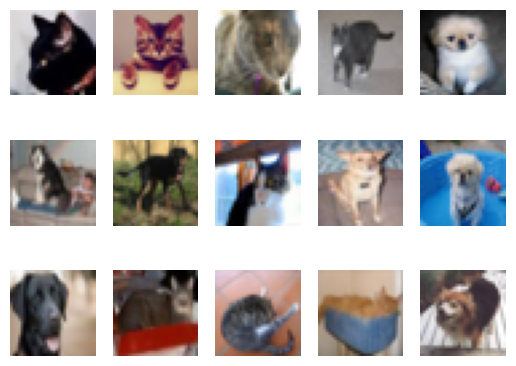

In [5]:
import matplotlib.pyplot as plt

k = 0
for images, labels in train_loader:
    # since batch_size = 1, there is only 1 image in `images`
    image = images[0]
    # place the colour channel at the end, instead of at the beginning
    img = np.transpose(image, [1,2,0])
    # normalize pixel intensity values to [0, 1]
    img = img / 2 + 0.5
    plt.subplot(3, 5, k+1)
    plt.axis('off')
    plt.imshow(img)

    k += 1
    if k > 14:
        break

### Part (b) -- 3 pt

How many training examples do we have for the combined `cat` and `dog` classes? 
What about validation examples? 
What about test examples?

There are 8,000 images of cats and dogs for the training set, and 2,000 images for the validation set. There are also 2,000 test examples. 
- CIFAR-10 has 5,000 training images per class, thus for cats and dogs, there are 10,000 in total
- The function "get_data_loader" splits the data into 80% training set and 20% validiation set.
- There are 1,000 test images per class

### Part (c) -- 3pt

Why do we need a validation set when training our model? What happens if we judge the 
performance of our models using the training set loss/error instead of the validation
set loss/error?

We need a validation set when training our model to measure how well the model performs on unseen data while training. It helps us choose the best model, hyperparamters, and stopping point.
If we judge the performance based on just training loss/error, the model could look like it is improving just because it is memorizing the training examples. This is called overfitting. Training error might be very low, while the validation error reamins high, meaning that the model does not do well when generalizing to new images.  

## Part 2. Training [15 pt]

We define two neural networks, a `LargeNet` and `SmallNet`.
We'll be training the networks in this section.

You won't understand fully what these networks are doing until
the next few classes, and that's okay. For this assignment, please
focus on learning how to train networks, and how hyperparameters affect
training.

In [6]:
class LargeNet(nn.Module):
    def __init__(self):
        super(LargeNet, self).__init__()
        self.name = "large"
        self.conv1 = nn.Conv2d(3, 5, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(5, 10, 5)
        self.fc1 = nn.Linear(10 * 5 * 5, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 10 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        x = x.squeeze(1) # Flatten to [batch_size]
        return x

In [7]:
class SmallNet(nn.Module):
    def __init__(self):
        super(SmallNet, self).__init__()
        self.name = "small"
        self.conv = nn.Conv2d(3, 5, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc = nn.Linear(5 * 7 * 7, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = self.pool(x)
        x = x.view(-1, 5 * 7 * 7)
        x = self.fc(x)
        x = x.squeeze(1) # Flatten to [batch_size]
        return x

In [8]:
small_net = SmallNet()
large_net = LargeNet()

### Part (a) -- 2pt

The methods `small_net.parameters()` and `large_net.parameters()`
produces an iterator of all the trainable parameters of the network.
These parameters are torch tensors containing many scalar values. 

We haven't learned how how the parameters in these high-dimensional
tensors will be used, but we should be able to count the number
of parameters. Measuring the number of parameters in a network is
one way of measuring the "size" of a network.

What is the total number of parameters in `small_net` and in
`large_net`? (Hint: how many numbers are in each tensor?)

In [9]:
for param in small_net.parameters():
    print(param.shape)
for param in large_net.parameters():
    print(param.shape)

torch.Size([5, 3, 3, 3])
torch.Size([5])
torch.Size([1, 245])
torch.Size([1])
torch.Size([5, 3, 5, 5])
torch.Size([5])
torch.Size([10, 5, 5, 5])
torch.Size([10])
torch.Size([32, 250])
torch.Size([32])
torch.Size([1, 32])
torch.Size([1])


Total parameters of small_net: 386 parameters 
- Conv weights: 5*3*3*3=135
- Conv bias: 5
- Fully connected weights: 1*245=245
- Fully connected bias: 1
- Total: 135 + 5 + 245 + 1 = 386

Total parameters for large_net: 9705 parameters 
- conv1: 5*3*5*5 + 5 = 380
- conv2: 10*5*5*5 + 10 = 1260
- fc1: 32*250 + 32 = 8032
- fc2: 1*32 + 1 = 33
- Total: 380 + 1260 + 8032 + 33 = 9705 

### The function train_net

The function `train_net` below takes an untrained neural network (like `small_net` and `large_net`) and
several other parameters. You should be able to understand how this function works.
The figure below shows the high level training loop for a machine learning model:

![alt text](https://github.com/UTNeural/Lab2/blob/master/Diagram.png?raw=true)

In [13]:
def train_net(net, batch_size=64, learning_rate=0.01, num_epochs=30):
    ########################################################################
    # Train a classifier on cats vs dogs
    target_classes = ["cat", "dog"]
    ########################################################################
    # Fixed PyTorch random seed for reproducible result
    torch.manual_seed(1000)
    ########################################################################
    # Obtain the PyTorch data loader objects to load batches of the datasets
    train_loader, val_loader, test_loader, classes = get_data_loader(
            target_classes, batch_size)
    ########################################################################
    # Define the Loss function and optimizer
    # The loss function will be Binary Cross Entropy (BCE). In this case we
    # will use the BCEWithLogitsLoss which takes unnormalized output from
    # the neural network and scalar label.
    # Optimizer will be SGD with Momentum.
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)
    ########################################################################
    # Set up some numpy arrays to store the training/test loss/erruracy
    train_err = np.zeros(num_epochs)
    train_loss = np.zeros(num_epochs)
    val_err = np.zeros(num_epochs)
    val_loss = np.zeros(num_epochs)
    ########################################################################
    # Train the network
    # Loop over the data iterator and sample a new batch of training data
    # Get the output from the network, and optimize our loss function.
    start_time = time.time()
    for epoch in range(num_epochs):  # loop over the dataset multiple times
        total_train_loss = 0.0
        total_train_err = 0.0
        total_epoch = 0
        for i, data in enumerate(train_loader, 0):
            # Get the inputs
            inputs, labels = data
            labels = normalize_label(labels) # Convert labels to 0/1
            # Zero the parameter gradients
            optimizer.zero_grad()
            # Forward pass, backward pass, and optimize
            outputs = net(inputs)
            loss = criterion(outputs, labels.float())
            loss.backward()
            optimizer.step()
            # Calculate the statistics
            corr = (outputs > 0.0).squeeze().long() != labels
            total_train_err += int(corr.sum())
            total_train_loss += loss.item()
            total_epoch += len(labels)
        train_err[epoch] = float(total_train_err) / total_epoch
        train_loss[epoch] = float(total_train_loss) / (i+1)
        val_err[epoch], val_loss[epoch] = evaluate(net, val_loader, criterion)
        print(("Epoch {}: Train err: {}, Train loss: {} |"+
               "Validation err: {}, Validation loss: {}").format(
                   epoch + 1,
                   train_err[epoch],
                   train_loss[epoch],
                   val_err[epoch],
                   val_loss[epoch]))
        # Save the current model (checkpoint) to a file
        model_path = get_model_name(net.name, batch_size, learning_rate, epoch)
        torch.save(net.state_dict(), model_path)
    print('Finished Training')
    end_time = time.time()
    elapsed_time = end_time - start_time
    print("Total time elapsed: {:.2f} seconds".format(elapsed_time))
    # Write the train/test loss/err into CSV file for plotting later
    epochs = np.arange(1, num_epochs + 1)
    np.savetxt("{}_train_err.csv".format(model_path), train_err)
    np.savetxt("{}_train_loss.csv".format(model_path), train_loss)
    np.savetxt("{}_val_err.csv".format(model_path), val_err)
    np.savetxt("{}_val_loss.csv".format(model_path), val_loss)

### Part (b) -- 1pt

The parameters to the function `train_net` are hyperparameters of our neural network.
We made these hyperparameters easy to modify so that we can tune them later on. 

What are the default values of the parameters `batch_size`, `learning_rate`, 
and `num_epochs`?

- batch_size = 64
- learning_rate = 0.01
- num_ephochs = 30

### Part (c) -- 3 pt

What files are written to disk when we call `train_net` with `small_net`, and train for 5 epochs? Provide a list
of all the files written to disk, and what information the files contain.

Model checkpoint files (One checkpoint is saved after easy epoch, each file contains the network weights after that epoch):
- model_small_bs64_lr0.01_epoch0
- model_small_bs64_lr0.01_epoch1
- model_small_bs64_lr0.01_epoch2
- model_small_bs64_lr0.01_epoch3
- model_small_bs64_lr0.01_epoch4
 

Training statistics file (after training, 4 csv files are created using the final checkpoint name, epoch4)
- model_small_bs64_lr0.01_epoch4_train_err_.csv : training classification error
- model_small_bs64_lr0.01_epoch4_train_loss_.csv : training loss 
- model_small_bs64_lr0.01_epoch4_val_err_.csv : validation classification error 
- model_small_bs64_lr0.01_epoch4_val_loss_.csv : validation loss


### Part (d) -- 2pt

Train both `small_net` and `large_net` using the function `train_net` and its default parameters.
The function will write many files to disk, including a model checkpoint (saved values of model weights) 
at the end of each epoch.

If you are using Google Colab, you will need to mount Google Drive 
so that the files generated by `train_net` gets saved. We will be using
these files in part (d).
(See the Google Colab tutorial for more information about this.)

Report the total time elapsed when training each network. Which network took longer to train?
Why?

In [ ]:
# Since the function writes files to disk, you will need to mount
# your Google Drive. If you are working on the lab locally, you
# can comment out this code.

#from google.colab import drive
#drive.mount('/content/gdrive')

In [ ]:
# recording the total time taken to train the small network
small_net = SmallNet()
train_net(small_net, batch_size=64, learning_rate=0.01, num_epochs=30)

Epoch 1: Train err: 0.409625, Train loss: 0.6680866041183472 |Validation err: 0.38, Validation loss: 0.6529379468411207
Epoch 2: Train err: 0.3495, Train loss: 0.636650381565094 |Validation err: 0.372, Validation loss: 0.644148213788867
Epoch 3: Train err: 0.338, Train loss: 0.6187666630744935 |Validation err: 0.3375, Validation loss: 0.6197400242090225
Epoch 4: Train err: 0.3245, Train loss: 0.6040865285396576 |Validation err: 0.359, Validation loss: 0.627186669036746
Epoch 5: Train err: 0.316375, Train loss: 0.594923665523529 |Validation err: 0.333, Validation loss: 0.6169400922954082
Epoch 6: Train err: 0.309375, Train loss: 0.5862700350284576 |Validation err: 0.3285, Validation loss: 0.6125966534018517
Epoch 7: Train err: 0.3085, Train loss: 0.5833819851875305 |Validation err: 0.3295, Validation loss: 0.608515608124435
Epoch 8: Train err: 0.29775, Train loss: 0.5781815807819366 |Validation err: 0.3175, Validation loss: 0.6042346935719252
Epoch 9: Train err: 0.29725, Train loss: 0.5

In [ ]:
#recording the total time taken to train the large network
large_net = LargeNet()  
train_net(large_net, batch_size=64, learning_rate=0.01, num_epochs=30)

Epoch 1: Train err: 0.44475, Train loss: 0.6900203113555908 |Validation err: 0.4285, Validation loss: 0.6807542983442545
Epoch 2: Train err: 0.419125, Train loss: 0.6781901936531067 |Validation err: 0.413, Validation loss: 0.6741814073175192
Epoch 3: Train err: 0.39825, Train loss: 0.6658476033210754 |Validation err: 0.3895, Validation loss: 0.6518005970865488
Epoch 4: Train err: 0.374, Train loss: 0.6491246662139892 |Validation err: 0.415, Validation loss: 0.6677671857178211
Epoch 5: Train err: 0.355625, Train loss: 0.633103331565857 |Validation err: 0.355, Validation loss: 0.6295729540288448
Epoch 6: Train err: 0.341375, Train loss: 0.6160089151859284 |Validation err: 0.339, Validation loss: 0.616680096834898
Epoch 7: Train err: 0.324875, Train loss: 0.6004832179546357 |Validation err: 0.3295, Validation loss: 0.6078574452549219
Epoch 8: Train err: 0.312375, Train loss: 0.5828952312469482 |Validation err: 0.324, Validation loss: 0.5972189512103796
Epoch 9: Train err: 0.30725, Train l

The total time elapsed to train the small network was 456.26 seconds, and the time it took to train the large network was 388.36.
It took longer to train the smaller network. The measured time includes data loading and system overhead. The smaller network may have less efficiant operations for the hardware, whereas the larger network can use the computation more efficiently. 

### Part (e) - 2pt

Use the function `plot_training_curve` to display the trajectory of the 
training/validation error and the training/validation loss.
You will need to use the function `get_model_name` to generate the
argument to the `plot_training_curve` function.

Do this for both the small network and the large network. Include both plots
in your writeup.

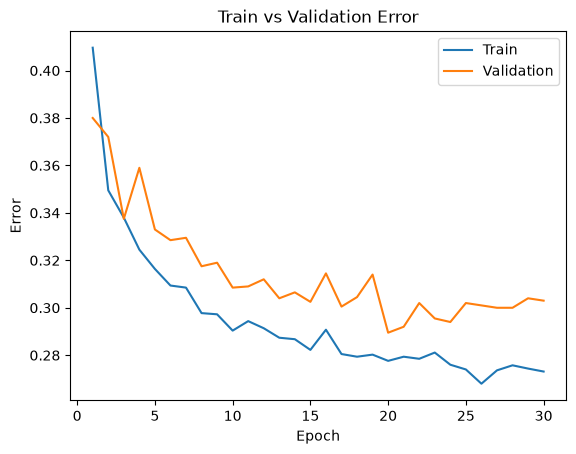

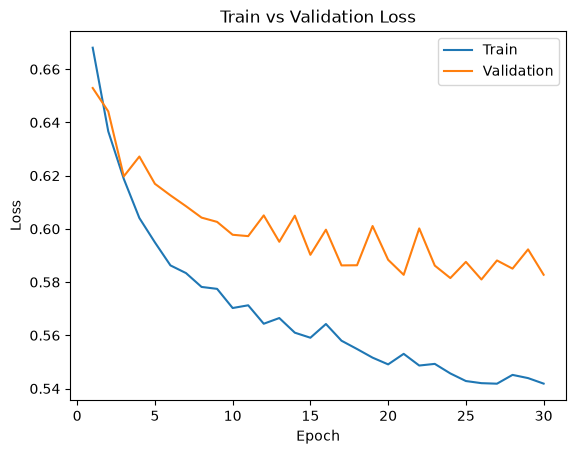

In [ ]:
#model_path = get_model_name("small", batch_size=??, learning_rate=??, epoch=29)
# for small network
plot_training_curve(get_model_name("small", batch_size=64, learning_rate=0.01, epoch=29))

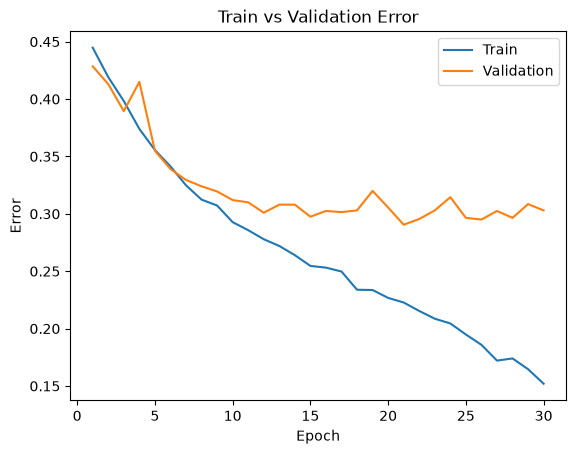

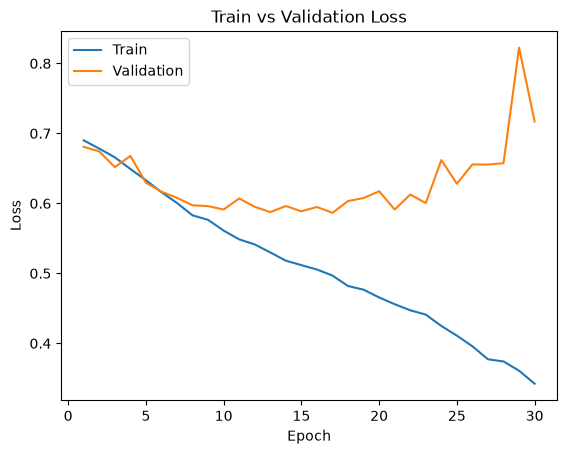

In [ ]:
# for large network
plot_training_curve(get_model_name("large", batch_size=64, learning_rate=0.01, epoch=29))

### Part (f) - 5pt

Describe what you notice about the training curve.
How do the curves differ for `small_net` and `large_net`?
Identify any occurences of underfitting and overfitting.

For small_net, both the training and validation error decrease during the first few epochs. The training error continues to decrease gradually, while the validation error fluctuates around 0.30 and improves only slightly. The training and validation curves remain relatively close, so there is no strong evidence of overfitting. The relatively high training error suggests that small_net may be slightly underfitting because its limited capacity prevents it from learning the data completely.

For large_net, the training error and loss decrease consistently throughout training. However, after approximately epoch 8-10, the validation error and loss stop improving and begin to fluctuate or increase, while the training performance continues improving. This growing gap between the training and validation curves indicates overfitting. The best performance likely occurs around the point where the validation error or loss is lowest, before the curves diverge.

Overall, large_net fits the training data better than small_net, but it overfits more noticeably. small_net generalizes more consistently but has slightly weaker performance and may be mildly underfit.

## Part 3. Optimization Parameters [12 pt]

For this section, we will work with `large_net` only.

### Part (a) - 3pt

Train `large_net` with all default parameters, except set `learning_rate=0.001`.
Does the model take longer/shorter to train?
Plot the training curve. Describe the effect of *lowering* the learning rate.

Epoch 1: Train err: 0.49875, Train loss: 0.6936983728408813 |Validation err: 0.49, Validation loss: 0.6925976295024157
Epoch 2: Train err: 0.48325, Train loss: 0.6923024954795838 |Validation err: 0.4695, Validation loss: 0.6917003747075796
Epoch 3: Train err: 0.469875, Train loss: 0.6912673392295837 |Validation err: 0.4625, Validation loss: 0.6909913923591375
Epoch 4: Train err: 0.46675, Train loss: 0.6902870445251464 |Validation err: 0.449, Validation loss: 0.6896635591983795
Epoch 5: Train err: 0.4545, Train loss: 0.6892736902236939 |Validation err: 0.4435, Validation loss: 0.6895225625485182
Epoch 6: Train err: 0.4515, Train loss: 0.6882340173721313 |Validation err: 0.437, Validation loss: 0.688451137393713
Epoch 7: Train err: 0.447875, Train loss: 0.6871999559402466 |Validation err: 0.4345, Validation loss: 0.6875279098749161
Epoch 8: Train err: 0.445375, Train loss: 0.686003095626831 |Validation err: 0.433, Validation loss: 0.6866629496216774
Epoch 9: Train err: 0.44075, Train los

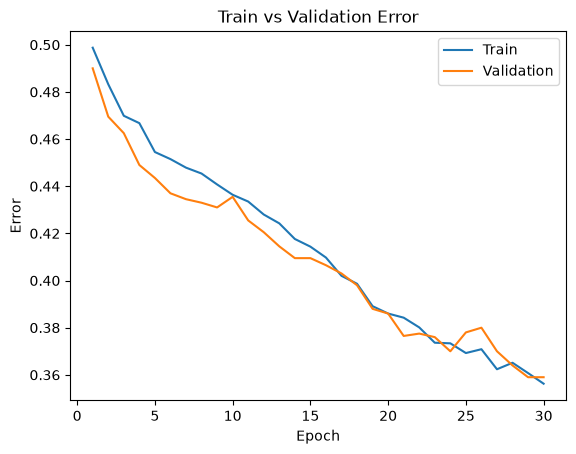

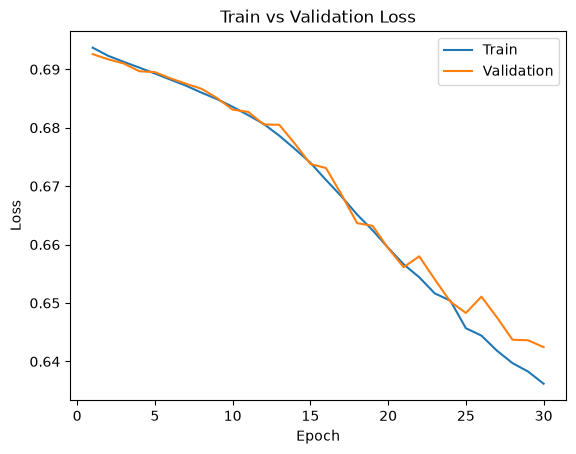

In [ ]:
# Note: When we re-construct the model, we start the training
# with *random weights*. If we omit this code, the values of
# the weights will still be the previously trained values.
large_net = LargeNet()
train_net(large_net, batch_size=64, learning_rate=0.001, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=64, learning_rate=0.001, epoch=29))

Lowering the learning rate from 0.01 to 0.001 decreased the training time from 388.36 seconds to 352.37 seconds. With learning_rate=0.001, both the training and validation error decrease gradually throughout the 30 epochs. The training and validation curves remain close together, and the validation loss does not diverge significantly from the training loss. Therefore, there is little evidence of overfitting. The lower learning rate makes smaller weight updates, so the model learns more slowly and may require more epochs to reach a low error. After 30 epochs, the error is still relatively high, suggesting that the model may be underfitting or has not had enough time to converge.

### Part (b) - 3pt

Train `large_net` with all default parameters, except set `learning_rate=0.1`. 
Does the model take longer/shorter to train?
Plot the training curve. Describe the effect of *increasing* the learning rate.

Epoch 1: Train err: 0.429875, Train loss: 0.6752145924568176 |Validation err: 0.378, Validation loss: 0.6376289371401072
Epoch 2: Train err: 0.358625, Train loss: 0.6348985934257507 |Validation err: 0.353, Validation loss: 0.6168579142540693
Epoch 3: Train err: 0.35125, Train loss: 0.624727258682251 |Validation err: 0.338, Validation loss: 0.6124672368168831
Epoch 4: Train err: 0.331, Train loss: 0.60360107421875 |Validation err: 0.351, Validation loss: 0.6450391616672277
Epoch 5: Train err: 0.319, Train loss: 0.594632473230362 |Validation err: 0.34, Validation loss: 0.6060001626610756
Epoch 6: Train err: 0.31025, Train loss: 0.5773915741443634 |Validation err: 0.321, Validation loss: 0.5941676832735538
Epoch 7: Train err: 0.301625, Train loss: 0.5711239471435546 |Validation err: 0.317, Validation loss: 0.6042191609740257
Epoch 8: Train err: 0.2875, Train loss: 0.5489215927124024 |Validation err: 0.34, Validation loss: 0.598825397901237
Epoch 9: Train err: 0.28975, Train loss: 0.551672

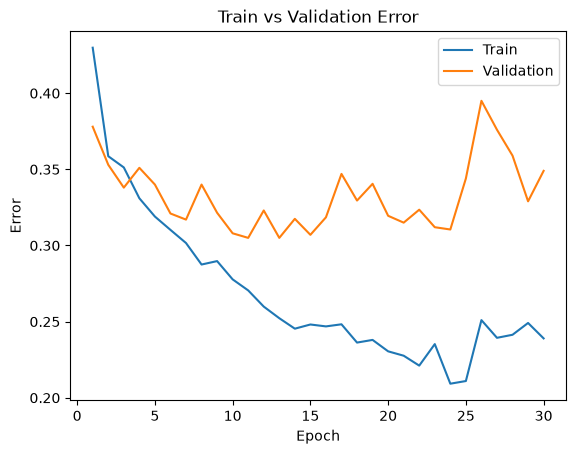

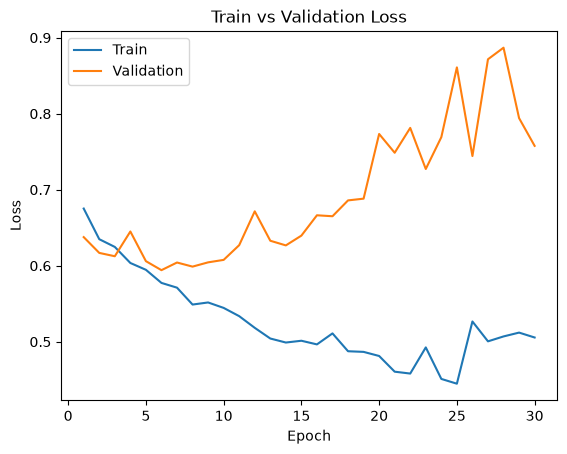

In [ ]:
large_net = LargeNet()
train_net(large_net, batch_size=64, learning_rate=0.1, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=64, learning_rate=0.1, epoch=29))

Increasing the learning rate to 0.1 decreased the training time to 355.78 seconds. However, graphs show that the training error and training loss generally decrease, meaning that the model continues improving on the training data. However, the validation error and validation loss become unstable and increase significantly after the early epochs. This creates a large gap between the training and validation curves and indicates strong overfitting or unstable updates.

A learning rate of 0.1 causes much larger weight updates. These updates can overshoot good solutions, causing the validation performance to fluctuate and worsen. The best validation performance occurs relatively early, before the validation curves begin to increase. Overall, 0.1 is too large for this model: although training performance improves, generalization becomes much worse compared with the default learning rate of 0.01.

### Part (c) - 3pt

Train `large_net` with all default parameters, including with `learning_rate=0.01`.
Now, set `batch_size=512`. Does the model take longer/shorter to train?
Plot the training curve. Describe the effect of *increasing* the batch size.

Epoch 1: Train err: 0.48175, Train loss: 0.6929379515349865 |Validation err: 0.478, Validation loss: 0.6926824003458023
Epoch 2: Train err: 0.457625, Train loss: 0.6924103982746601 |Validation err: 0.434, Validation loss: 0.6917425245046616
Epoch 3: Train err: 0.437, Train loss: 0.691650040447712 |Validation err: 0.4265, Validation loss: 0.6909129321575165
Epoch 4: Train err: 0.433625, Train loss: 0.6908450089395046 |Validation err: 0.424, Validation loss: 0.6897870749235153
Epoch 5: Train err: 0.434, Train loss: 0.6896936297416687 |Validation err: 0.424, Validation loss: 0.6881358474493027
Epoch 6: Train err: 0.43825, Train loss: 0.6883534491062164 |Validation err: 0.428, Validation loss: 0.6860133111476898
Epoch 7: Train err: 0.43925, Train loss: 0.6866872385144234 |Validation err: 0.426, Validation loss: 0.6836972683668137
Epoch 8: Train err: 0.435375, Train loss: 0.6849771030247211 |Validation err: 0.412, Validation loss: 0.6814650744199753
Epoch 9: Train err: 0.42375, Train loss: 

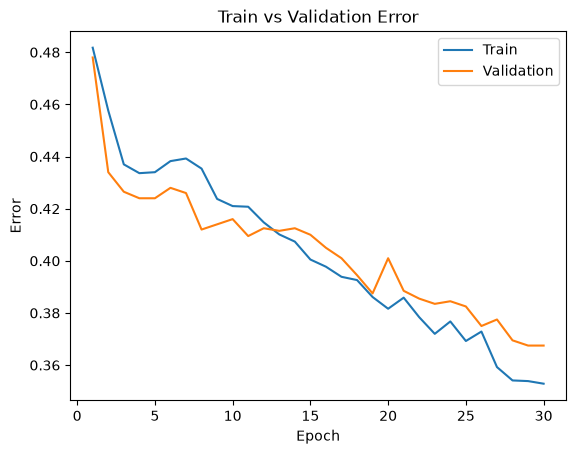

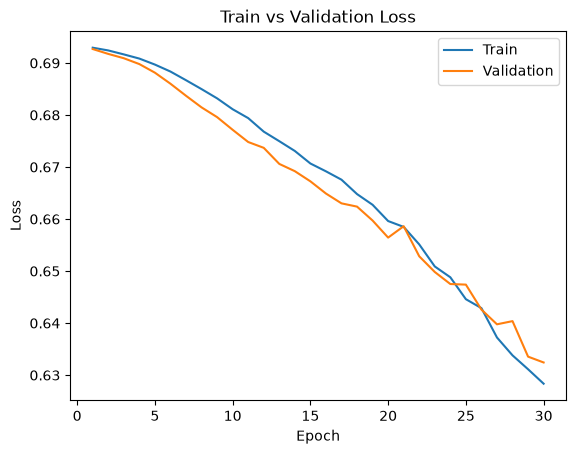

In [ ]:
large_net = LargeNet()
train_net(large_net, batch_size=512, learning_rate=0.01, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=512, learning_rate=0.01, epoch=29))

Increasing the batch size to 512 decreased the training time to 342.19 second. This is expected since each epoch uses fewer batches. With 8,000 training examples, a batch size of 64 requires approximately 125 batches per epoch, while a batch size of 512 requires only approximately 16 batches per epoch. Therefore, the optimizer performs fewer updates during each epoch.

The training and validation error both decrease over the 30 epochs, although the validation error fluctuates slightly. The training and validation loss also decrease together and remain relatively close. This suggests that the model is learning steadily, with no strong evidence of overfitting in this run.

Increasing the batch size produces more stable, less noisy gradient estimates and reduces the number of parameter updates, making training faster. However, the model may learn less flexibly because it receives fewer updates per epoch. In this experiment, the final validation error is approximately 37%.

### Part (d) - 3pt

Train `large_net` with all default parameters, including with `learning_rate=0.01`.
Now, set `batch_size=16`. Does the model take longer/shorter to train?
Plot the training curve. Describe the effect of *decreasing* the batch size.

Epoch 1: Train err: 0.432625, Train loss: 0.6776098030805587 |Validation err: 0.3745, Validation loss: 0.6529334607124329
Epoch 2: Train err: 0.3665, Train loss: 0.6396277079582214 |Validation err: 0.352, Validation loss: 0.6202217926979064
Epoch 3: Train err: 0.340375, Train loss: 0.611763548374176 |Validation err: 0.3425, Validation loss: 0.6225978240966797
Epoch 4: Train err: 0.310375, Train loss: 0.583930772960186 |Validation err: 0.3335, Validation loss: 0.5936324608325958
Epoch 5: Train err: 0.29975, Train loss: 0.5643941404819488 |Validation err: 0.3265, Validation loss: 0.5934103174209595
Epoch 6: Train err: 0.281375, Train loss: 0.5449857948422432 |Validation err: 0.3035, Validation loss: 0.5832211289405823
Epoch 7: Train err: 0.269375, Train loss: 0.5272681354284287 |Validation err: 0.319, Validation loss: 0.621401073217392
Epoch 8: Train err: 0.263375, Train loss: 0.5111728370785713 |Validation err: 0.315, Validation loss: 0.5854083404541016
Epoch 9: Train err: 0.2475, Train

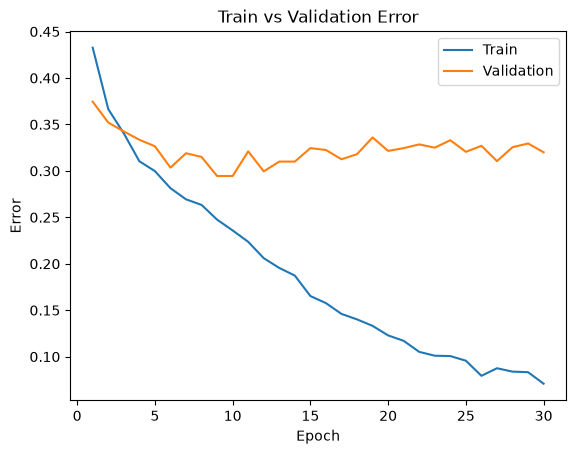

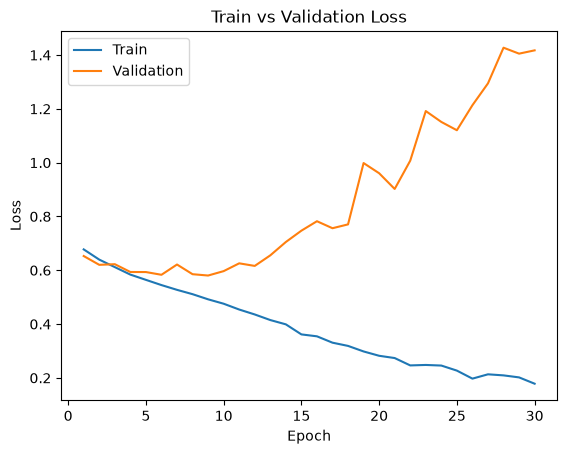

In [ ]:
large_net = LargeNet()
train_net(large_net, batch_size=16, learning_rate=0.01, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=16, learning_rate=0.01, epoch=29))

Decreasing the vatch size to 12 increased the training time to 424.10 seconds. This is because each epoch requires more batches and therefore, more parameter updates. With 8,000 training examples, a batch size of 16 requires approximately 500 batches per epoch, compared with approximately 125 batches when the batch size is 64.

The training error and training loss decrease consistently, reaching approximately 8% error and 0.18 loss. However, the validation loss begins increasing significantly after about epoch 8, eventually reaching approximately 1.4. The validation error also fluctuates and remains around 30-33% while the training error continues to fall.

This large gap between training and validation performance indicates strong overfitting. The smaller batch size produces noisier gradient estimates and many more updates. This can help the model fit the training data very closely, but in this experiment it reduces generalization to the validation data. Overall, decreasing the batch size made training slower and caused more noticeable overfitting.

## Part 4. Hyperparameter Search [6 pt]

### Part (a) - 2pt

Based on the plots from above, choose another set of values for the hyperparameters (network, batch_size, learning_rate)
that you think would help you improve the validation accuracy. Justify your choice.

- large_net with batch size of 64 and a learning rate of 0.005

Batch size 64 used since it was the most accurate compared to 512. But did not cause severe overfitting like 16. 
The learning rate of 0.1 caused unstable validation performance and overfitting, while 0.001 learned too slowly and still had relatively high validation error after 30 epochs. A learning rate of 0.005 is between these values and should provide more stable updates than 0.1 while learning faster than 0.001.

### Part (b) - 1pt

Train the model with the hyperparameters you chose in part(a), and include the training curve.

Epoch 1: Train err: 0.498125, Train loss: 0.693441210269928 |Validation err: 0.463, Validation loss: 0.692121647298336
Epoch 2: Train err: 0.449375, Train loss: 0.6902769436836242 |Validation err: 0.4325, Validation loss: 0.6869329456239939
Epoch 3: Train err: 0.443625, Train loss: 0.6848875179290771 |Validation err: 0.423, Validation loss: 0.6802606284618378
Epoch 4: Train err: 0.429125, Train loss: 0.6795436472892761 |Validation err: 0.4205, Validation loss: 0.6714036520570517
Epoch 5: Train err: 0.41125, Train loss: 0.6712780375480651 |Validation err: 0.386, Validation loss: 0.6615424510091543
Epoch 6: Train err: 0.380625, Train loss: 0.657154773235321 |Validation err: 0.3635, Validation loss: 0.6462700515985489
Epoch 7: Train err: 0.373375, Train loss: 0.6469872641563416 |Validation err: 0.352, Validation loss: 0.6381314136087894
Epoch 8: Train err: 0.365, Train loss: 0.6349571533203126 |Validation err: 0.3575, Validation loss: 0.6278157122433186
Epoch 9: Train err: 0.351375, Train

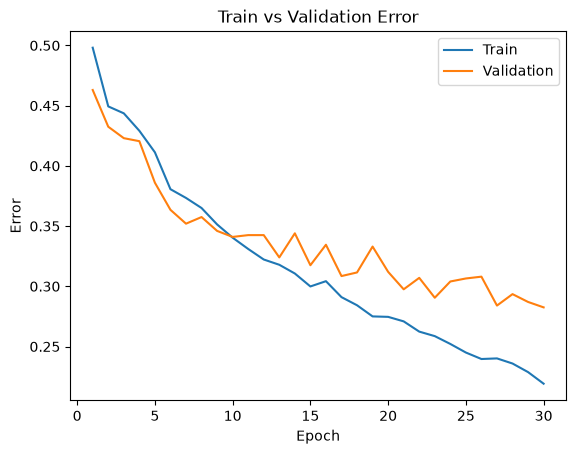

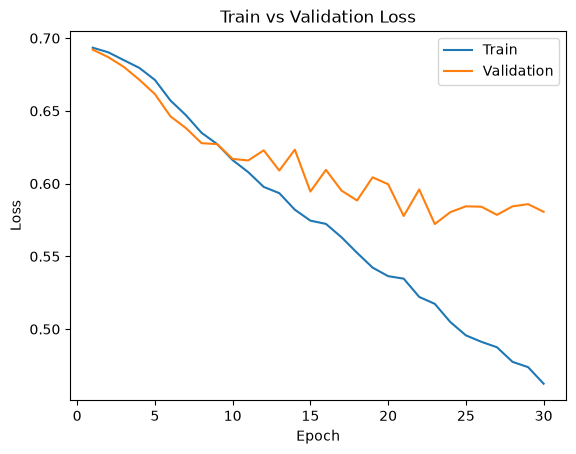

In [ ]:
large_net = LargeNet()
train_net(large_net, batch_size=64, learning_rate=0.005, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=64, learning_rate=0.005, epoch=29))

### Part (c) - 2pt

Based on your result from Part(a), suggest another set of hyperparameter values to try. 
Justify your choice.

- increase batch size to 128, keep a learning rate of 0.005

Batch size of 512 trained faster, but had a weaker validation performance, while batch size of 16 had substanisial overfitting. Currently, there seems to be some overfitting in teh graphs which could be reduced by increasing the batch size. 

### Part (d) - 1pt

Train the model with the hyperparameters you chose in part(c), and include the training curve.

Epoch 1: Train err: 0.487875, Train loss: 0.693385036218734 |Validation err: 0.444, Validation loss: 0.6909762062132359
Epoch 2: Train err: 0.45125, Train loss: 0.6888883634219094 |Validation err: 0.4155, Validation loss: 0.685368612408638
Epoch 3: Train err: 0.4365, Train loss: 0.6843413776821561 |Validation err: 0.4195, Validation loss: 0.6805739812552929
Epoch 4: Train err: 0.430875, Train loss: 0.6794616002885122 |Validation err: 0.415, Validation loss: 0.6749377213418484
Epoch 5: Train err: 0.418625, Train loss: 0.6742368917616587 |Validation err: 0.4105, Validation loss: 0.6712135635316372
Epoch 6: Train err: 0.39975, Train loss: 0.668240279432327 |Validation err: 0.399, Validation loss: 0.6664445698261261
Epoch 7: Train err: 0.388625, Train loss: 0.6615137741679237 |Validation err: 0.393, Validation loss: 0.6584289744496346
Epoch 8: Train err: 0.381875, Train loss: 0.6546839295871674 |Validation err: 0.382, Validation loss: 0.6526732593774796
Epoch 9: Train err: 0.370375, Train 

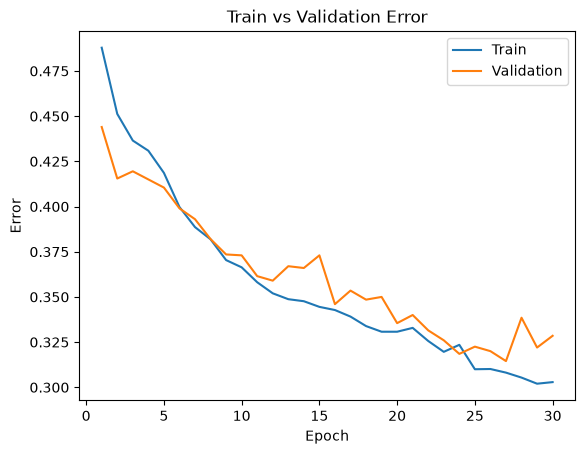

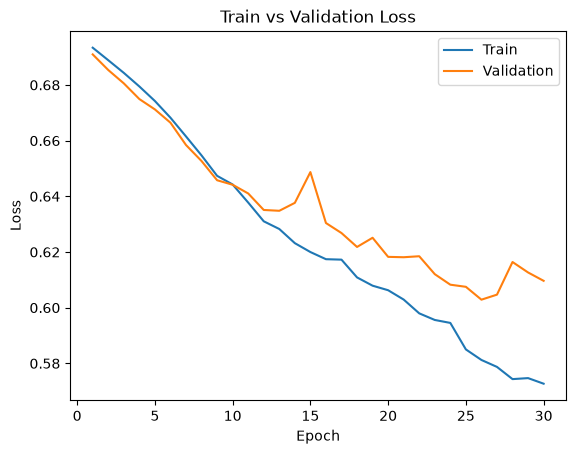

In [14]:
large_net = LargeNet()
train_net(large_net, batch_size=128, learning_rate=0.005, num_epochs=30)
plot_training_curve(get_model_name("large", batch_size=128, learning_rate=0.005, epoch=29))

## Part 4. Evaluating the Best Model [15 pt]


### Part (a) - 1pt

Choose the **best** model that you have so far. This means choosing the best model checkpoint,
including the choice of `small_net` vs `large_net`, the `batch_size`, `learning_rate`, 
**and the epoch number**.

Modify the code below to load your chosen set of weights to the model object `net`.

In [16]:
net = LargeNet()
model_path = get_model_name(net.name, batch_size=64, learning_rate=0.005, epoch=29)
state = torch.load(model_path)
net.load_state_dict(state)

<All keys matched successfully>

### Part (b) - 2pt

Justify your choice of model from part (a).

The model does show moderate overfitting because its training error was 0.2191 compared with a validation error of 0.2825, but its validation performance was still the best overall. Therefore, this checkpoint provides the best balance between accuracy and generalization among all the experiments.

Large Net:
- achieved a lower validation error than small_net, indicating better performance on unseen validation images

Batch size = 64:
- because smaller batches, especially 16, produced substantially more overfitting, while the larger batch size of 512 had worse validation performance

Learning Rate = 0.005:
- learning rate of 0.001 learned too slowly, while 0.01 and 0.1 resulted in greater instability or overfitting

Epoch-30 checkpoint:
- it had the lowest validation classification error among the checkpoints tested, approximately 0.2825

### Part (c) - 2pt

Using the code in Part 0, any code from lecture notes, or any code that you write,
compute and report the **test classification error** for your chosen model.

In [18]:
# If you use the `evaluate` function provided in part 0, you will need to 
# set batch_size > 1
train_loader, val_loader, test_loader, classes = get_data_loader(
    target_classes=["cat", "dog"], 
    batch_size=64)

# Use the same loss used during training 
criterion = nn.BCEWithLogitsLoss()

# Evaluate the model on the test set
test_err, test_loss = evaluate(net, test_loader, criterion) 
# from evaluate function - classification rule 
#corr = (outputs > 0.0).squeeze().long() != labels

print("Test classification error:", test_err)
print("Test classification accuracy:", 1 - test_err)

Test classification error: 0.2985
Test classification accuracy: 0.7015


### Part (d) - 3pt

How does the test classification error compare with the **validation error**?
Explain why you would expect the test error to be *higher* than the validation error.

### Part (e) - 2pt

Why did we only use the test data set at the very end?
Why is it important that we use the test data as little as possible?

### Part (f) - 5pt

How does the your best CNN model compare with an 2-layer ANN model (no convolutional layers) on classifying cat and dog images. You can use a 2-layer ANN architecture similar to what you used in Lab 1. You should explore different hyperparameter settings to determine how well you can do on the validation dataset. Once satisified with the performance, you may test it out on the test data.

Hint: The ANN in lab 1 was applied on greyscale images. The cat and dog images are colour (RGB) and so you will need to flatted and concatinate all three colour layers before feeding them into an ANN.